In [5]:
 #PROJECT CONFIGURATION
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import io
import time
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import yfinance as yf

from scipy import stats
import statsmodels.api as sm

# -----------------------------
# Global configuration
# -----------------------------

START_DATE = "2005-01-01"
END_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")

BASE_CURRENCY = "USD"

# Number of currencies to long/short
N_LONG = 2
N_SHORT = 2

# Transaction cost in decimal terms.
# Example:
# 10 bps = 0.0010
TRANSACTION_COST_BPS = 10

# Annualized target volatility
TARGET_VOL = 0.10

# Lookback for volatility estimation
VOL_LOOKBACK = 12

# Risk-free proxy
RISK_FREE_RATE = 0.0

# Annualization factor for monthly data
MONTHS_PER_YEAR = 12

# Reproducibility
np.random.seed(42)

# Output folders
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = Path("outputs")
CHART_DIR = Path("charts")

for folder in [RAW_DIR, PROCESSED_DIR, OUTPUT_DIR, CHART_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project initialized.")
print(f"Backtest period: {START_DATE} → {END_DATE}")

Project initialized.
Backtest period: 2005-01-01 → 2026-10-12


In [9]:

#  INSTALL REQUIRED PACKAGES
!pip -q install yfinance statsmodels scipy seaborn

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [10]:
# ============================================================
# CREATE CURRENCY UNIVERSE
# ============================================================

# All currencies are expressed relative to USD.
#
# FX ticker:
# EURUSD=X means USD per EUR
#
# USDJPY=X means JPY per USD, therefore it must be inverted
# to obtain USD per JPY.

CURRENCY_CONFIG = {
    "EUR": {
        "ticker": "EURUSD=X",
        "inverse": False,
        "fred": "IR3TIB01DEM156N",
        "description": "Euro"
    },
    "GBP": {
        "ticker": "GBPUSD=X",
        "inverse": False,
        "fred": "IR3TIB01GBM156N",
        "description": "British Pound"
    },
    "AUD": {
        "ticker": "AUDUSD=X",
        "inverse": False,
        "fred": "IR3TIB01AUM156N",
        "description": "Australian Dollar"
    },
    "JPY": {
        "ticker": "USDJPY=X",
        "inverse": True,
        "fred": "IR3TIB01JPM156N",
        "description": "Japanese Yen"
    },
    "CAD": {
        "ticker": "USDCAD=X",
        "inverse": True,
        "fred": "IR3TIB01CAM156N",
        "description": "Canadian Dollar"
    },
    "CHF": {
        "ticker": "USDCHF=X",
        "inverse": True,
        "fred": "IR3TIB01CHM156N",
        "description": "Swiss Franc"
    }
}

USD_RATE_SERIES = "IR3TIB01USM156N"

CURRENCIES = list(CURRENCY_CONFIG.keys())

print("Currencies:", CURRENCIES)

Currencies: ['EUR', 'GBP', 'AUD', 'JPY', 'CAD', 'CHF']


In [8]:

# DOWNLOAD DAILY FX DATA

# Ensure configuration variables exist in case this cell is executed before the setup cell
if "START_DATE" not in globals():
    START_DATE = "2005-01-01"
if "END_DATE" not in globals():
    END_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")
def download_fx_prices(start=START_DATE, end=END_DATE):
    """
    Download daily FX close prices from Yahoo Finance.

    Returns
    -------
    pd.DataFrame
        USD-normalized FX prices.
    """

    normalized = {}

    for currency, config in CURRENCY_CONFIG.items():

        ticker = config["ticker"]

        try:
            print(f"Downloading {currency} ({ticker})...")

            data = yf.download(
                ticker,
                start=start,
                end=end,
                progress=False,
                auto_adjust=False
            )

            if data.empty:
                raise ValueError(f"No data returned for {ticker}")

            # Handle both normal and MultiIndex Yahoo responses
            if isinstance(data.columns, pd.MultiIndex):
                close = data["Close"].iloc[:, 0]
            else:
                close = data["Close"]

            close = pd.to_numeric(close, errors="coerce").dropna()

            if config["inverse"]:
                close = 1.0 / close

            normalized[currency] = close

        except Exception as exc:
            print(f"ERROR: {currency}: {exc}")

    fx = pd.DataFrame(normalized)

    fx.index = pd.to_datetime(fx.index)
    fx = fx.sort_index()

    return fx


fx_daily = download_fx_prices()

print("\nFX data shape:", fx_daily.shape)
display(fx_daily.tail())


FX data shape: (5664, 6)


,EUR,GBP,AUD,JPY,CAD,CHF
Date,,,,,,
2026-10-05,1.125454,1.324293,0.69518,0.006340,0.701562,1.207569
2026-10-06,1.121705,1.321860,0.69673,0.006331,0.701080,1.203196
2026-10-07,1.125353,1.326682,0.69818,0.006317,0.703621,1.201663
2026-10-08,1.120134,1.321493,0.69640,0.006327,0.701370,1.200509
2026-10-09,1.121302,1.322909,0.69590,0.006327,0.703052,1.202819


In [11]:

#  MONTH-END FX PRICES

def to_month_end_prices(df):
    """
    Convert daily observations into month-end observations.
    """

    if df.empty:
        raise ValueError("FX dataframe is empty.")

    monthly = (
        df
        .resample("ME")
        .last()
        .dropna(how="all")
    )

    return monthly


fx_monthly = to_month_end_prices(fx_daily)

fx_monthly.to_csv(PROCESSED_DIR / "fx_monthly.csv")

print("Monthly FX data:")
display(fx_monthly.tail())

Monthly FX data:


,EUR,GBP,AUD,JPY,CAD,CHF
Date,,,,,,
2026-06-30,1.142204,1.325399,0.688240,0.006176,0.703779,1.238237
2026-07-31,1.152353,1.346094,0.702519,0.006243,0.713715,1.241049
2026-08-31,1.158896,1.354041,0.716300,0.006245,0.719471,1.236338
2026-09-30,1.134083,1.323276,0.698900,0.006353,0.704657,1.198725
2026-10-31,1.121302,1.322909,0.695900,0.006327,0.703052,1.202819


In [12]:

#  FRED RATE DOWNLOAD


def download_fred_series(series_id, start=START_DATE, end=END_DATE):
    """
    Download a FRED series through the public fredgraph CSV endpoint.

    This avoids requiring a FRED API key for the standard historical
    series used in this research project.
    """

    url = (
        "https://fred.stlouisfed.org/graph/fredgraph.csv"
        f"?id={series_id}"
        f"&cosd={start}"
        f"&coed={end}"
    )

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        df = pd.read_csv(io.StringIO(response.text))

        if df.shape[1] < 2:
            raise ValueError("Unexpected FRED response.")

        df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0])

        df.iloc[:, 1] = pd.to_numeric(
            df.iloc[:, 1],
            errors="coerce"
        )

        df = df.set_index(df.columns[0])

        series = df.iloc[:, 0].rename(series_id)

        return series

    except Exception as exc:
        raise RuntimeError(
            f"Could not download FRED series {series_id}: {exc}"
        )


rates = {}

# USD
rates["USD"] = download_fred_series(USD_RATE_SERIES)

# Foreign currencies
for currency, config in CURRENCY_CONFIG.items():

    try:
        rates[currency] = download_fred_series(config["fred"])
        print(f"Downloaded rate: {currency}")

    except Exception as exc:
        print(f"Rate download failed for {currency}: {exc}")

rates_monthly = pd.DataFrame(rates)

rates_monthly = rates_monthly.resample("ME").last()

rates_monthly = rates_monthly.sort_index()

rates_monthly.to_csv(PROCESSED_DIR / "rates_monthly.csv")

display(rates_monthly.tail())

Downloaded rate: EUR
Downloaded rate: GBP
Downloaded rate: AUD
Downloaded rate: JPY
Downloaded rate: CAD
Downloaded rate: CHF


,USD,EUR,GBP,AUD,JPY,CAD,CHF
observation_date,,,,,,,
2026-04-30,3.77,2.175300,NaN,4.34,1.24182,2.2720,-0.039834
2026-05-31,3.72,2.226100,NaN,4.43,1.27409,2.2925,-0.039444
2026-06-30,3.77,2.339000,NaN,4.46,1.41200,2.2725,-0.045120
2026-07-31,3.82,2.425391,NaN,4.48,1.45845,2.2580,-0.044891
2026-08-31,3.82,2.513143,NaN,4.51,NaN,2.2800,-0.045000


In [13]:

def data_quality_report(df, name="DataFrame"):
    """
    Produce a compact data-quality report.
    """

    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100,
        "unique": df.nunique()
    })

    print(f"\n{name}")
    print("=" * len(name))

    display(report)

    if df.empty:
        raise ValueError(f"{name} is empty.")

    return report


fx_quality = data_quality_report(
    fx_monthly,
    "Monthly FX Data"
)

rate_quality = data_quality_report(
    rates_monthly,
    "Monthly Interest Rate Data"
)


Monthly FX Data


,dtype,missing,missing_pct,unique
EUR,float64,0,0.00000,261
GBP,float64,0,0.00000,260
AUD,float64,16,6.10687,243
JPY,float64,0,0.00000,262
CAD,float64,0,0.00000,256
CHF,float64,0,0.00000,260



Monthly Interest Rate Data


,dtype,missing,missing_pct,unique
USD,float64,1,0.384615,154
EUR,float64,0,0.000000,260
GBP,float64,7,2.692308,238
AUD,float64,0,0.000000,187
JPY,float64,1,0.384615,137
CAD,float64,0,0.000000,237
CHF,float64,0,0.000000,250


In [14]:

#ALIGN DATA


# Common monthly sample
common_index = (
    fx_monthly.index
    .intersection(rates_monthly.index)
)

fx = fx_monthly.loc[common_index].copy()

rates = rates_monthly.loc[common_index].copy()

# Forward fill rates because monthly interest rates may have
# publication gaps. We do not forward-fill FX prices.
rates = rates.ffill()

# Remove periods without complete information
valid = (
    fx.notna().all(axis=1)
    &
    rates.notna().all(axis=1)
)

fx = fx.loc[valid]
rates = rates.loc[valid]

print("Aligned observations:", len(fx))
print("Start:", fx.index.min())
print("End:", fx.index.max())

display(rates.tail())

Aligned observations: 244
Start: 2006-05-31 00:00:00
End: 2026-08-31 00:00:00


,USD,EUR,GBP,AUD,JPY,CAD,CHF
2026-04-30,3.77,2.175300,3.71,4.34,1.24182,2.2720,-0.039834
2026-05-31,3.72,2.226100,3.71,4.43,1.27409,2.2925,-0.039444
2026-06-30,3.77,2.339000,3.71,4.46,1.41200,2.2725,-0.045120
2026-07-31,3.82,2.425391,3.71,4.48,1.45845,2.2580,-0.044891
2026-08-31,3.82,2.513143,3.71,4.51,1.45845,2.2800,-0.045000


In [15]:

# FX RETURNS

# Since all FX prices are now:
#
# USD per 1 unit of foreign currency
#
# positive return = foreign currency appreciated against USD.

fx_returns = fx.pct_change()

fx_returns = fx_returns.dropna(how="all")

display(fx_returns.tail())

,EUR,GBP,AUD,JPY,CAD,CHF
2026-04-30,0.019607,0.023973,0.041666,-0.002141,0.018798,0.011789
2026-05-31,-0.002727,-0.003271,0.004636,0.005739,-0.008097,0.008805
2026-06-30,-0.019806,-0.014169,-0.039335,-0.016384,-0.029988,-0.029643
2026-07-31,0.008885,0.015615,0.020747,0.010863,0.014117,0.002271
2026-08-31,0.005679,0.005904,0.019617,0.000381,0.008065,-0.003796


In [16]:

#INTEREST RATE DIFFERENTIAL / CARRY


# Carry = foreign short-term rate - USD short-term rate

carry_spread = pd.DataFrame(index=rates.index)

for currency in CURRENCIES:

    carry_spread[currency] = (
        rates[currency] - rates["USD"]
    )

display(carry_spread.tail())

,EUR,GBP,AUD,JPY,CAD,CHF
2026-04-30,-1.594700,-0.06,0.57,-2.52818,-1.4980,-3.809833
2026-05-31,-1.493900,-0.01,0.71,-2.44591,-1.4275,-3.759444
2026-06-30,-1.431000,-0.06,0.69,-2.35800,-1.4975,-3.815120
2026-07-31,-1.394609,-0.11,0.66,-2.36155,-1.5620,-3.864891
2026-08-31,-1.306857,-0.11,0.69,-2.36155,-1.5400,-3.865000


In [17]:

# FEATURE ENGINEERING


features = {}

for currency in CURRENCIES:

    temp = pd.DataFrame(index=fx.index)

    temp["fx_price"] = fx[currency]

    temp["fx_return"] = fx_returns[currency]

    temp["foreign_rate"] = rates[currency]

    temp["usd_rate"] = rates["USD"]

    temp["carry_spread"] = carry_spread[currency]

    # Rolling annualized volatility
    temp["volatility_12m"] = (
        temp["fx_return"]
        .rolling(VOL_LOOKBACK)
        .std()
        * np.sqrt(12)
    )

    # Momentum features
    temp["momentum_3m"] = (
        temp["fx_price"]
        .pct_change(3)
    )

    temp["momentum_12m"] = (
        temp["fx_price"]
        .pct_change(12)
    )

    features[currency] = temp


# Combine into one long-form dataframe
feature_df = (
    pd.concat(
        features,
        names=["currency", "date"]
    )
    .reset_index()
)

display(feature_df.tail())

,currency,date,fx_price,fx_return,foreign_rate,usd_rate,carry_spread,volatility_12m,momentum_3m,momentum_12m
1459,CHF,2026-04-30,1.264926,0.011789,-0.039834,3.77,-3.809833,0.068288,-0.033078,0.041565
1460,CHF,2026-05-31,1.276064,0.008805,-0.039444,3.72,-3.759444,0.068446,-0.013309,0.048886
1461,CHF,2026-06-30,1.238237,-0.029643,-0.045120,3.77,-3.815120,0.069995,-0.009559,-0.011578
1462,CHF,2026-07-31,1.241049,0.002271,-0.044891,3.82,-3.864891,0.067321,-0.018876,0.009233
1463,CHF,2026-08-31,1.236338,-0.003796,-0.045000,3.82,-3.865000,0.065770,-0.031131,-0.008963


In [18]:

# CARRY RANKING

# Ensure carry_spread exists before ranking
if "carry_spread" not in globals():
    carry_spread = pd.DataFrame(index=rates.index)
    for currency in CURRENCIES:
        carry_spread[currency] = rates[currency] - rates["USD"]
carry_rank = carry_spread.rank(
    axis=1,
    ascending=True,
    method="first"
)

display(carry_rank.tail())

,EUR,GBP,AUD,JPY,CAD,CHF
2026-04-30,3.0,5.0,6.0,2.0,4.0,1.0
2026-05-31,3.0,5.0,6.0,2.0,4.0,1.0
2026-06-30,4.0,5.0,6.0,2.0,3.0,1.0
2026-07-31,4.0,5.0,6.0,2.0,3.0,1.0
2026-08-31,4.0,5.0,6.0,2.0,3.0,1.0


In [19]:

# LAGGED CARRY SIGNAL


def create_carry_positions(
    carry,
    n_long=N_LONG,
    n_short=N_SHORT
):
    """
    Construct dollar-neutral carry positions.

    Highest carry:
        +1

    Lowest carry:
        -1

    Middle currencies:
         0

    Positions are equal-weighted within the long and short books.
    """

    positions = pd.DataFrame(
        0.0,
        index=carry.index,
        columns=carry.columns
    )

    for date in carry.index:

        row = carry.loc[date].dropna()

        if len(row) < n_long + n_short:
            continue

        ranked = row.sort_values()

        short_names = ranked.iloc[:n_short].index

        long_names = ranked.iloc[-n_long:].index

        positions.loc[date, long_names] = 1.0 / n_long

        positions.loc[date, short_names] = -1.0 / n_short

    return positions


raw_positions = create_carry_positions(carry_spread)

# IMPORTANT:
#
# Signal observed at t
# Position used during t+1
#
# Therefore shift by one period.

positions = raw_positions.shift(1)

display(positions.tail())

,EUR,GBP,AUD,JPY,CAD,CHF
2026-04-30,0.0,0.5,0.5,-0.5,0.0,-0.5
2026-05-31,0.0,0.5,0.5,-0.5,0.0,-0.5
2026-06-30,0.0,0.5,0.5,-0.5,0.0,-0.5
2026-07-31,0.0,0.5,0.5,-0.5,0.0,-0.5
2026-08-31,0.0,0.5,0.5,-0.5,0.0,-0.5


In [20]:

# GROSS CARRY STRATEGY RETURNS


# FX return contribution
fx_pnl = positions * fx_returns

# Interest-rate differential contribution
#
# Annualized rate differential / 12
carry_pnl = (
    positions
    * carry_spread.shift(1)
    / 100
    / 12
)

# Total gross return
gross_currency_returns = (
    fx_pnl
    + carry_pnl
)

gross_strategy_return = (
    gross_currency_returns
    .sum(axis=1)
)

gross_strategy_return.name = "Gross_Carry_Return"

display(gross_strategy_return.tail())

2026-04-30    0.030776
2026-05-31   -0.003736
2026-06-30   -0.000861
2026-07-31    0.014448
2026-08-31    0.017291
Freq: ME, Name: Gross_Carry_Return, dtype: float64

In [21]:

#  PORTFOLIO TURNOVER


def calculate_turnover(weights):
    """
    One-way turnover proxy based on absolute changes in
    portfolio weights.
    """

    turnover = (
        weights
        .diff()
        .abs()
        .sum(axis=1)
        / 2
    )

    return turnover.fillna(0)


turnover = calculate_turnover(positions)

display(turnover.tail())

2026-04-30    0.0
2026-05-31    0.0
2026-06-30    0.0
2026-07-31    0.0
2026-08-31    0.0
Freq: ME, dtype: float64

In [22]:

#TRANSACTION COST MODEL


transaction_cost_rate = (
    TRANSACTION_COST_BPS / 10000
)

transaction_cost = (
    turnover
    * transaction_cost_rate
)

transaction_cost.name = "Transaction_Cost"

display(transaction_cost.tail())

2026-04-30    0.0
2026-05-31    0.0
2026-06-30    0.0
2026-07-31    0.0
2026-08-31    0.0
Freq: ME, Name: Transaction_Cost, dtype: float64

In [23]:

#  VOLATILITY TARGETING


realized_strategy_vol = (
    gross_strategy_return
    .rolling(VOL_LOOKBACK)
    .std()
    * np.sqrt(12)
)

# Avoid extreme leverage
MAX_LEVERAGE = 2.0

vol_scale = (
    TARGET_VOL
    / realized_strategy_vol
)

vol_scale = (
    vol_scale
    .replace([np.inf, -np.inf], np.nan)
    .clip(upper=MAX_LEVERAGE)
    .fillna(1.0)
)

scaled_gross_return = (
    gross_strategy_return
    * vol_scale
)

scaled_transaction_cost = (
    transaction_cost
    * vol_scale
)

net_strategy_return = (
    scaled_gross_return
    - scaled_transaction_cost
)

net_strategy_return.name = "Net_Carry_Return"

display(
    pd.DataFrame({
        "Gross": scaled_gross_return,
        "TransactionCost": scaled_transaction_cost,
        "Net": net_strategy_return
    }).tail()
)

,Gross,TransactionCost,Net
2026-04-30,0.061552,0.0,0.061552
2026-05-31,-0.007472,0.0,-0.007472
2026-06-30,-0.001721,0.0,-0.001721
2026-07-31,0.028897,0.0,0.028897
2026-08-31,0.034583,0.0,0.034583


In [24]:

# FX BENCHMARK


# Equal-weight foreign-currency basket versus USD.

benchmark_weights = pd.DataFrame(
    1 / len(CURRENCIES),
    index=fx_returns.index,
    columns=CURRENCIES
)

benchmark_return = (
    benchmark_weights
    * fx_returns
).sum(axis=1)

benchmark_return.name = "Equal_Weight_FX"

benchmark_nav = (
    1 + benchmark_return.fillna(0)
).cumprod()

display(benchmark_return.tail())

2026-04-30    0.018949
2026-05-31    0.000847
2026-06-30   -0.024888
2026-07-31    0.012083
2026-08-31    0.005975
Freq: ME, Name: Equal_Weight_FX, dtype: float64

In [25]:

# CUMULATIVE PERFORMANCE

strategy_nav = (
    1 + net_strategy_return.fillna(0)
).cumprod()

gross_nav = (
    1 + scaled_gross_return.fillna(0)
).cumprod()

strategy_nav.name = "Carry Strategy"

gross_nav.name = "Gross Carry"

benchmark_nav.name = "Equal Weight FX"

performance_df = pd.concat(
    [
        strategy_nav,
        gross_nav,
        benchmark_nav
    ],
    axis=1
)

display(performance_df.tail())

,Carry Strategy,Gross Carry,Equal Weight FX
2026-04-30,0.998508,1.014698,0.939793
2026-05-31,0.991047,1.007117,0.940589
2026-06-30,0.989341,1.005383,0.917180
2026-07-31,1.017930,1.034435,0.928263
2026-08-31,1.053133,1.070209,0.933809


In [26]:

# DRAWDOWN


def calculate_drawdown(nav):
    """
    Calculate percentage drawdown from historical peak.
    """

    peak = nav.cummax()

    drawdown = nav / peak - 1

    return drawdown


strategy_drawdown = calculate_drawdown(strategy_nav)

benchmark_drawdown = calculate_drawdown(
    benchmark_nav
)

In [27]:

 #PERFORMANCE METRICS


def calculate_metrics(
    returns,
    risk_free=RISK_FREE_RATE
):
    """
    Calculate professional portfolio performance statistics.
    """

    returns = pd.Series(returns).dropna()

    if len(returns) < 12:
        raise ValueError(
            "Not enough observations for reliable metrics."
        )

    n_months = len(returns)

    cumulative_return = (
        (1 + returns).prod() - 1
    )

    cagr = (
        (1 + cumulative_return)
        ** (12 / n_months)
        - 1
    )

    annual_vol = (
        returns.std()
        * np.sqrt(12)
    )

    annual_return = (
        returns.mean() * 12
    )

    sharpe = (
        (annual_return - risk_free)
        / annual_vol
        if annual_vol > 0
        else np.nan
    )

    downside = (
        returns[returns < 0]
        .std()
        * np.sqrt(12)
    )

    sortino = (
        annual_return / downside
        if downside > 0
        else np.nan
    )

    nav = (1 + returns).cumprod()

    drawdown = calculate_drawdown(nav)

    max_drawdown = drawdown.min()

    skewness = stats.skew(returns)

    kurtosis = stats.kurtosis(
        returns,
        fisher=True
    )

    var_95 = returns.quantile(0.05)

    expected_shortfall = (
        returns[returns <= var_95]
        .mean()
    )

    worst_month = returns.min()

    best_month = returns.max()

    return pd.Series({
        "Cumulative Return": cumulative_return,
        "CAGR": cagr,
        "Annualized Return": annual_return,
        "Annualized Volatility": annual_vol,
        "Sharpe Ratio": sharpe,
        "Sortino Ratio": sortino,
        "Maximum Drawdown": max_drawdown,
        "Skewness": skewness,
        "Excess Kurtosis": kurtosis,
        "VaR 95%": var_95,
        "Expected Shortfall 95%": expected_shortfall,
        "Worst Month": worst_month,
        "Best Month": best_month,
        "Observations": n_months
    })


strategy_metrics = calculate_metrics(
    net_strategy_return
)

benchmark_metrics = calculate_metrics(
    benchmark_return
)

metrics_table = pd.DataFrame({
    "FX Carry Strategy": strategy_metrics,
    "Equal-Weight FX": benchmark_metrics
})

display(
    metrics_table.style.format(
        lambda x:
        f"{x:.2%}"
        if abs(x) < 10
        else f"{x:.2f}"
    )
)

,FX Carry Strategy,Equal-Weight FX
Cumulative Return,5.31%,-6.62%
CAGR,0.25%,-0.34%
Annualized Return,0.74%,-0.08%
Annualized Volatility,9.88%,7.25%
Sharpe Ratio,7.52%,-1.05%
Sortino Ratio,11.92%,-1.64%
Maximum Drawdown,-52.05%,-32.52%
Skewness,-23.42%,2.37%
Excess Kurtosis,-3.12%,96.23%
VaR 95%,-4.65%,-3.09%


In [28]:

# CARRY PREDICTABILITY REGRESSION


regression_results = []

for currency in CURRENCIES:

    df = pd.DataFrame({
        "future_return": fx_returns[currency].shift(-1),
        "carry": carry_spread[currency]
    }).dropna()

    if len(df) < 24:
        continue

    X = sm.add_constant(df["carry"])

    y = df["future_return"]

    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 3}
    )

    regression_results.append({
        "Currency": currency,
        "Alpha": model.params.get("const", np.nan),
        "Carry_Coefficient": model.params.get(
            "carry",
            np.nan
        ),
        "t_stat": model.tvalues.get(
            "carry",
            np.nan
        ),
        "p_value": model.pvalues.get(
            "carry",
            np.nan
        ),
        "R_squared": model.rsquared
    })


regression_table = pd.DataFrame(
    regression_results
)

display(regression_table)

,Currency,Alpha,Carry_Coefficient,t_stat,p_value,R_squared
0,EUR,-0.001233,-0.001548,-0.976526,0.328804,0.005296
1,GBP,-0.000649,-0.003999,-1.400904,0.161243,0.019244
2,AUD,0.000994,-0.000400,-0.284446,0.776069,0.000452
3,JPY,-0.002223,-0.000724,-0.741754,0.458237,0.002603
4,CAD,-0.001212,-0.002432,-0.984019,0.325106,0.005007
5,CHF,0.001095,-0.000547,-0.500963,0.616397,0.000807


In [29]:

# CRASH / STRESS PERIOD ANALYSIS


STRESS_PERIODS = {
    "Global Financial Crisis": (
        "2008-01-01",
        "2009-06-30"
    ),

    "COVID Shock": (
        "2020-02-01",
        "2020-05-31"
    ),

    "2022 Rate Shock": (
        "2022-01-01",
        "2022-12-31"
    )
}


def period_return(returns, start, end):

    subset = returns.loc[start:end].dropna()

    if subset.empty:
        return np.nan

    return (1 + subset).prod() - 1


stress_results = []

for name, (start, end) in STRESS_PERIODS.items():

    stress_results.append({
        "Period": name,
        "Carry Strategy":
            period_return(
                net_strategy_return,
                start,
                end
            ),
        "FX Benchmark":
            period_return(
                benchmark_return,
                start,
                end
            )
    })


stress_table = pd.DataFrame(
    stress_results
).set_index("Period")

display(
    stress_table.style.format(
        "{:.2%}"
    )
)

,Carry Strategy,FX Benchmark
Period,,
Global Financial Crisis,-18.22%,-3.43%
COVID Shock,-7.62%,-1.43%
2022 Rate Shock,1.13%,-7.19%


In [30]:

#  CURRENCY CONTRIBUTION


currency_contribution = (
    scaled_gross_return
    .to_frame("Portfolio")
)

# Average contribution by currency
average_contribution = (
    gross_currency_returns
    .mean()
    .sort_values()
)

display(
    average_contribution.to_frame(
        "Average Monthly Contribution"
    )
)

,Average Monthly Contribution
CAD,-0.000848
CHF,-0.000425
GBP,-0.000076
JPY,0.000305
EUR,0.000418
AUD,0.000630


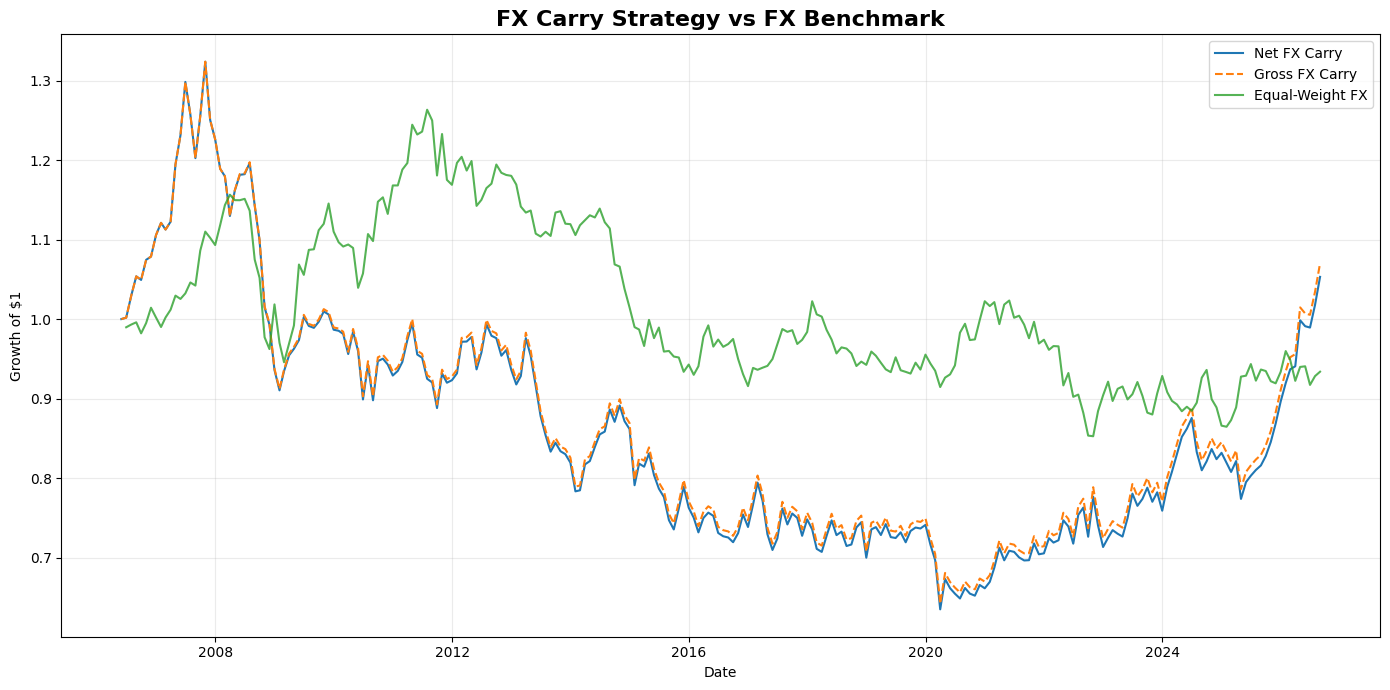

In [31]:

# CHART: CUMULATIVE PERFORMANCE


plt.figure(figsize=(14, 7))

plt.plot(
    strategy_nav,
    label="Net FX Carry"
)

plt.plot(
    gross_nav,
    label="Gross FX Carry",
    linestyle="--"
)

plt.plot(
    benchmark_nav,
    label="Equal-Weight FX",
    alpha=0.8
)

plt.title(
    "FX Carry Strategy vs FX Benchmark",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Growth of $1")

plt.xlabel("Date")

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "cumulative_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


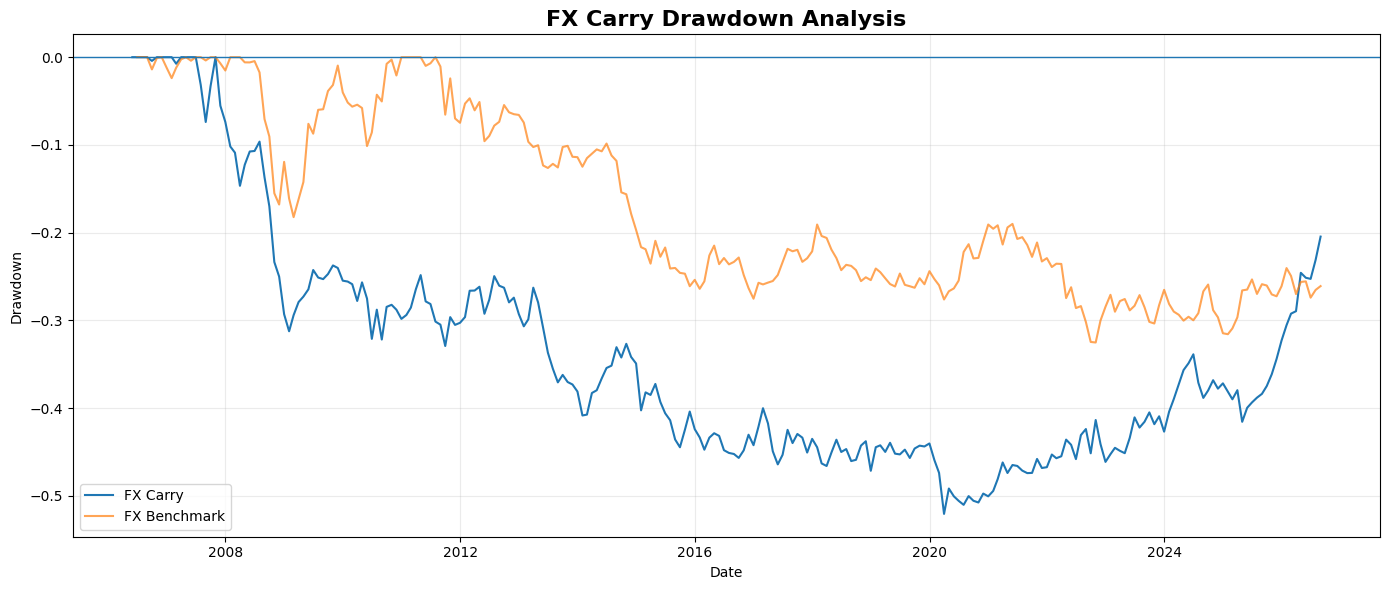

In [32]:

#  CHART: DRAWDOWN


plt.figure(figsize=(14, 6))

plt.plot(
    strategy_drawdown,
    label="FX Carry"
)

plt.plot(
    benchmark_drawdown,
    label="FX Benchmark",
    alpha=0.7
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "FX Carry Drawdown Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Drawdown")

plt.xlabel("Date")

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "drawdown.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


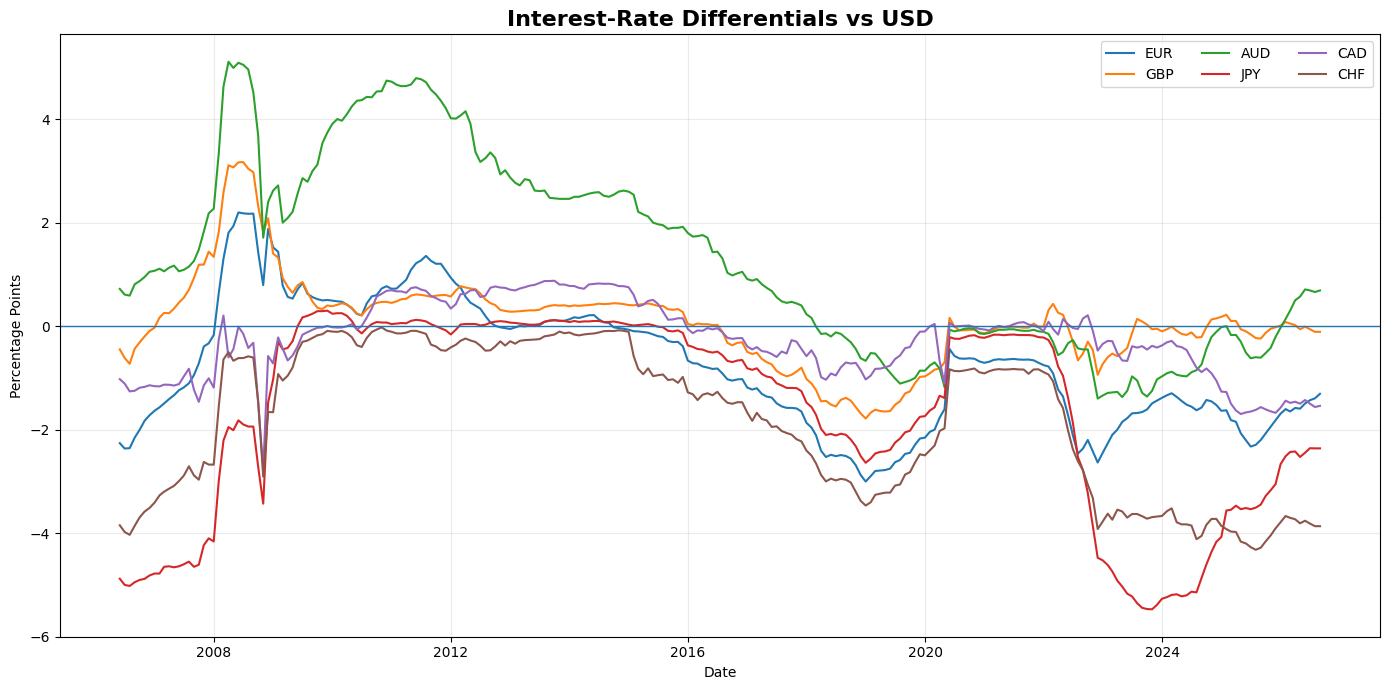

In [33]:

# CHART: CARRY SPREADS


plt.figure(figsize=(14, 7))

for currency in CURRENCIES:

    plt.plot(
        carry_spread[currency],
        label=currency
    )

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Interest-Rate Differentials vs USD",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Percentage Points")

plt.xlabel("Date")

plt.legend(
    ncol=3
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "carry_spreads.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

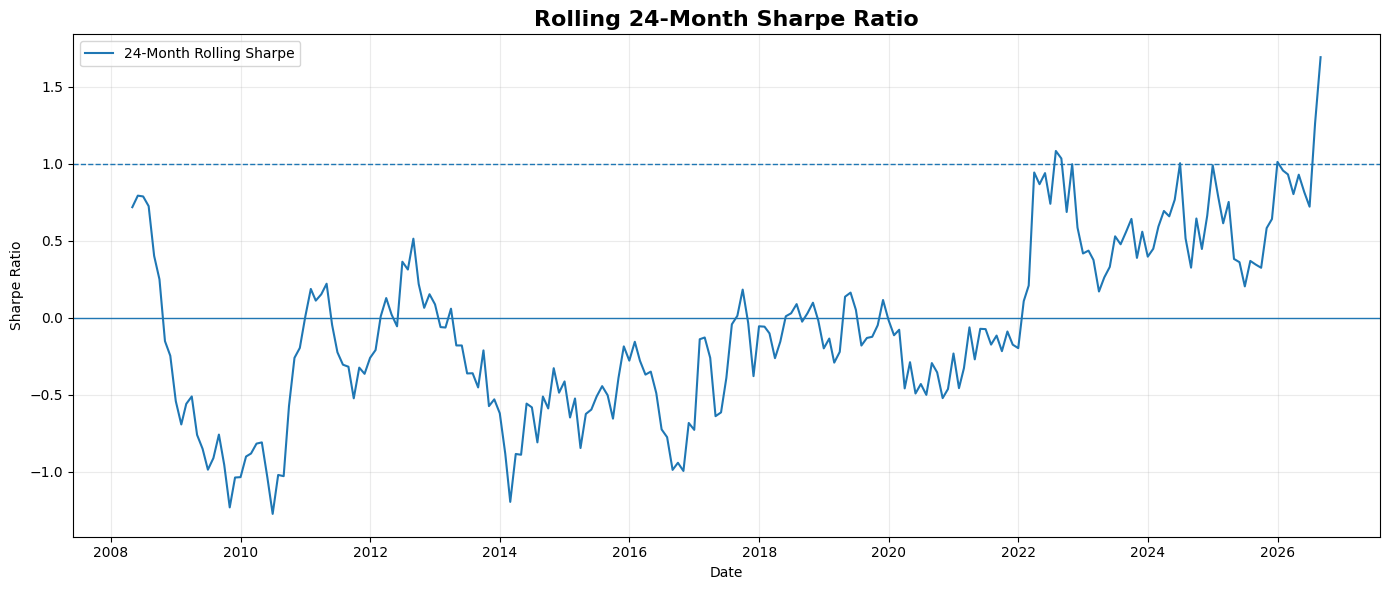

In [34]:

# ROLLING SHARPE


rolling_mean = (
    net_strategy_return
    .rolling(24)
    .mean()
    * 12
)

rolling_vol = (
    net_strategy_return
    .rolling(24)
    .std()
    * np.sqrt(12)
)

rolling_sharpe = (
    rolling_mean / rolling_vol
)

plt.figure(figsize=(14, 6))

plt.plot(
    rolling_sharpe,
    label="24-Month Rolling Sharpe"
)

plt.axhline(
    0,
    linewidth=1
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Rolling 24-Month Sharpe Ratio",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Sharpe Ratio")

plt.xlabel("Date")

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "rolling_sharpe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

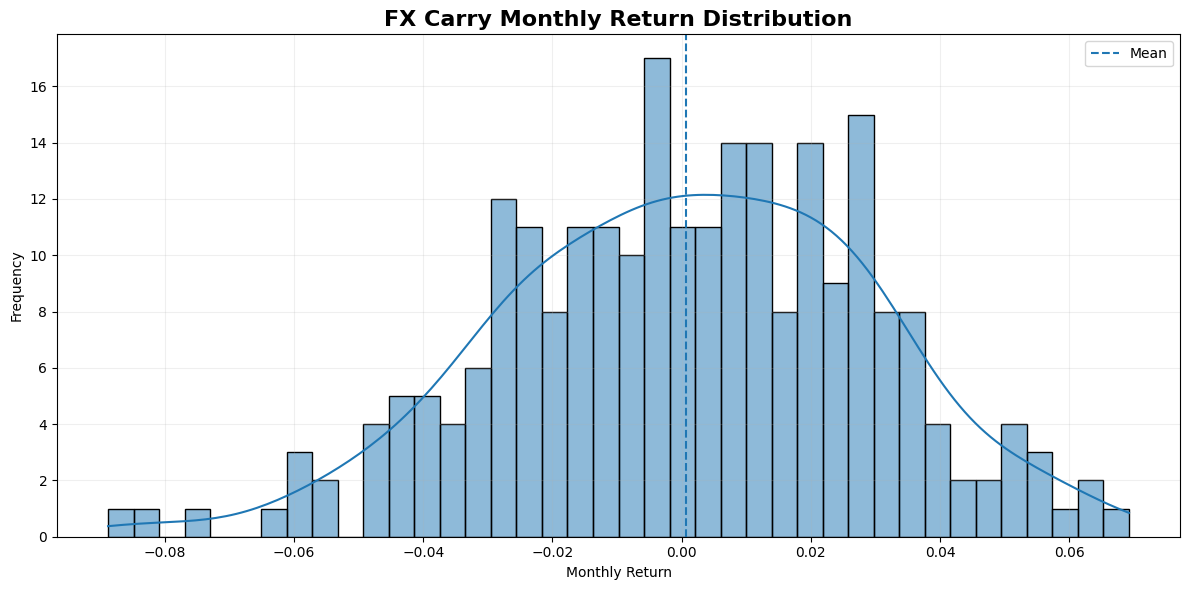

In [35]:

#  RETURN DISTRIBUTION


plt.figure(figsize=(12, 6))

sns.histplot(
    net_strategy_return.dropna(),
    bins=40,
    kde=True
)

plt.axvline(
    net_strategy_return.mean(),
    linestyle="--",
    label="Mean"
)

plt.title(
    "FX Carry Monthly Return Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Monthly Return")

plt.ylabel("Frequency")

plt.legend()

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "return_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

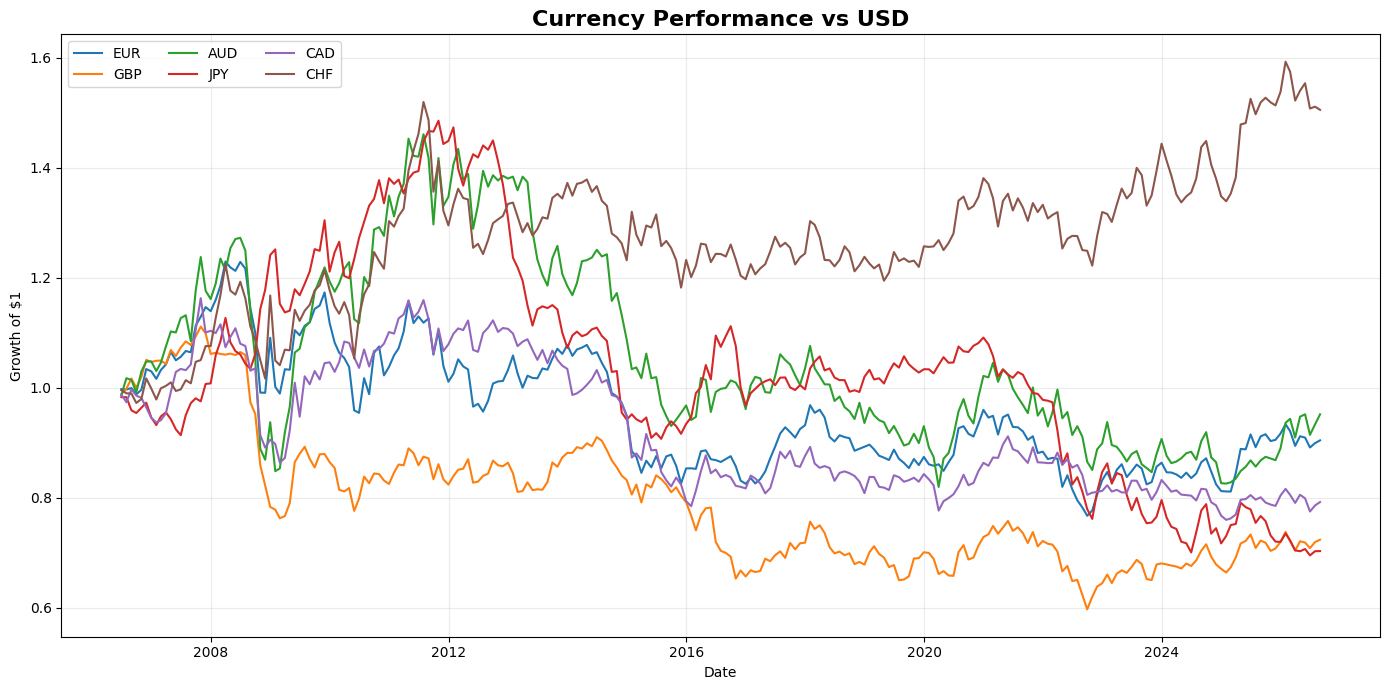

In [36]:

#  CURRENCY PERFORMANCE


currency_performance = (
    (1 + fx_returns)
    .cumprod()
)

plt.figure(figsize=(14, 7))

for currency in CURRENCIES:

    plt.plot(
        currency_performance[currency],
        label=currency
    )

plt.title(
    "Currency Performance vs USD",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Growth of $1")

plt.xlabel("Date")

plt.legend(
    ncol=3
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "currency_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

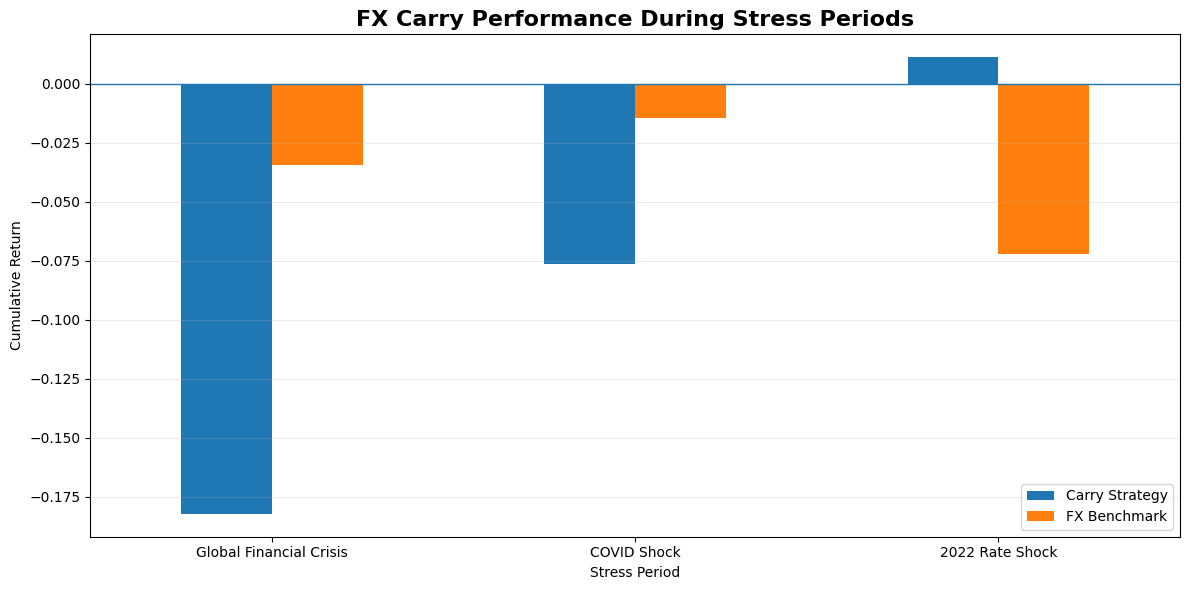

In [37]:

#  CRASH PERIOD PERFORMANCE

plot_data = stress_table.copy()

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "FX Carry Performance During Stress Periods",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Cumulative Return")

ax.set_xlabel("Stress Period")

ax.axhline(
    0,
    linewidth=1
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "stress_periods.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
#
#  FINAL RESEARCH SUMMARY
# 

summary = pd.DataFrame({
    "Metric": [
        "CAGR",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Sortino Ratio",
        "Maximum Drawdown",
        "Skewness",
        "VaR 95%",
        "Expected Shortfall 95%",
        "Worst Month"
    ],

    "FX Carry": [
        strategy_metrics["CAGR"],
        strategy_metrics["Annualized Volatility"],
        strategy_metrics["Sharpe Ratio"],
        strategy_metrics["Sortino Ratio"],
        strategy_metrics["Maximum Drawdown"],
        strategy_metrics["Skewness"],
        strategy_metrics["VaR 95%"],
        strategy_metrics["Expected Shortfall 95%"],
        strategy_metrics["Worst Month"]
    ],

    "Equal-Weight FX": [
        benchmark_metrics["CAGR"],
        benchmark_metrics["Annualized Volatility"],
        benchmark_metrics["Sharpe Ratio"],
        benchmark_metrics["Sortino Ratio"],
        benchmark_metrics["Maximum Drawdown"],
        benchmark_metrics["Skewness"],
        benchmark_metrics["VaR 95%"],
        benchmark_metrics["Expected Shortfall 95%"],
        benchmark_metrics["Worst Month"]
    ]
})

display(
    summary.style.format(
        {
            "FX Carry": "{:.2%}",
            "Equal-Weight FX": "{:.2%}"
        }
    )
)

,Metric,FX Carry,Equal-Weight FX
0,CAGR,0.25%,-0.34%
1,Annualized Volatility,9.88%,7.25%
2,Sharpe Ratio,7.52%,-1.05%
3,Sortino Ratio,11.92%,-1.64%
4,Maximum Drawdown,-52.05%,-32.52%
5,Skewness,-23.42%,2.37%
6,VaR 95%,-4.65%,-3.09%
7,Expected Shortfall 95%,-6.06%,-4.57%
8,Worst Month,-8.88%,-7.11%


In [39]:

# EXPORT RESEARCH OUTPUTS


# Performance
metrics_table.to_csv(
    OUTPUT_DIR / "performance_metrics.csv"
)

# Positions
positions.to_csv(
    OUTPUT_DIR / "portfolio_positions.csv"
)

# FX returns
fx_returns.to_csv(
    OUTPUT_DIR / "fx_returns.csv"
)

# Carry
carry_spread.to_csv(
    OUTPUT_DIR / "carry_spreads.csv"
)

# Strategy returns
pd.DataFrame({
    "Gross_Return": scaled_gross_return,
    "Transaction_Cost": scaled_transaction_cost,
    "Net_Return": net_strategy_return,
    "Turnover": turnover
}).to_csv(
    OUTPUT_DIR / "strategy_returns.csv"
)

# Stress tests
stress_table.to_csv(
    OUTPUT_DIR / "stress_test_results.csv"
)

# Regression
regression_table.to_csv(
    OUTPUT_DIR / "carry_regression.csv",
    index=False
)

print("All research outputs exported.")

All research outputs exported.


In [40]:

# FINAL DIAGNOSTICS


print("=" * 70)
print("FX CARRY TRADE RESEARCH ENGINE — FINAL DIAGNOSTICS")
print("=" * 70)

print(f"Sample start:       {fx.index.min().date()}")
print(f"Sample end:         {fx.index.max().date()}")
print(f"Observations:       {len(fx)}")
print(f"Currencies:         {len(CURRENCIES)}")
print(f"Long currencies:    {N_LONG}")
print(f"Short currencies:   {N_SHORT}")
print(f"Target volatility:  {TARGET_VOL:.1%}")
print(
    f"Transaction cost:   "
    f"{TRANSACTION_COST_BPS} bps"
)

print("\nPERFORMANCE")
print("-" * 70)

print(
    f"CAGR:               "
    f"{strategy_metrics['CAGR']:.2%}"
)

print(
    f"Volatility:         "
    f"{strategy_metrics['Annualized Volatility']:.2%}"
)

print(
    f"Sharpe:             "
    f"{strategy_metrics['Sharpe Ratio']:.2f}"
)

print(
    f"Sortino:            "
    f"{strategy_metrics['Sortino Ratio']:.2f}"
)

print(
    f"Maximum Drawdown:   "
    f"{strategy_metrics['Maximum Drawdown']:.2%}"
)

print(
    f"Skewness:           "
    f"{strategy_metrics['Skewness']:.2f}"
)

print(
    f"VaR 95%:            "
    f"{strategy_metrics['VaR 95%']:.2%}"
)

print(
    f"Expected Shortfall: "
    f"{strategy_metrics['Expected Shortfall 95%']:.2%}"
)

print(
    f"Worst Month:        "
    f"{strategy_metrics['Worst Month']:.2%}"
)

print("\nResearch engine completed successfully.")

FX CARRY TRADE RESEARCH ENGINE — FINAL DIAGNOSTICS
Sample start:       2006-05-31
Sample end:         2026-08-31
Observations:       244
Currencies:         6
Long currencies:    2
Short currencies:   2
Target volatility:  10.0%
Transaction cost:   10 bps

PERFORMANCE
----------------------------------------------------------------------
CAGR:               0.25%
Volatility:         9.88%
Sharpe:             0.08
Sortino:            0.12
Maximum Drawdown:   -52.05%
Skewness:           -0.23
VaR 95%:            -4.65%
Expected Shortfall: -6.06%
Worst Month:        -8.88%

Research engine completed successfully.
